# Додаткове завдання з pandas
Вітаю! В цьому завданні будемо працювати з даними з опитування щодо зарплат ІТ спеціалістів на рексурсі DOU від грудня 2022 року. Впевнена, це буде цікаве дослідження, а заразом і практика pandas :)
Цей аналіз може бути корисним людині, яка обирає напрям роботи в ІТ і хоче зрозуміти тенденції. За якісного виконання цього аналізу, цей проєкт можна сміливо додавати у Ваше портфоліо!

1. Зчитайте дані з файлу `2022_dec_raw.csv`. Увага! Тут необхідно використати аргумент `pd.read_csv` `sep=';'`, бо розділювач в даних - крапка з комою.

In [1]:
import os
import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

DATA_PATH = next(p for p in ['2022_dec_raw.csv', '../Матеріали/2022_dec_raw.csv'] if os.path.exists(p))
df = pd.read_csv(DATA_PATH, sep=';')
df.head(3)

,Timestamp,Ви працюєте зараз в ІТ?,Де ви зараз живете?,В якій області ви зараз живете?,"Зарплата у $$$ за місяць, лише ставка після сплати податків",Ваша стать,Ваш вік,Яка у вас освіта?,Чи є у вас науковий ступінь?,Знання англійської мови,Оберіть вашу посаду,Ваш тайтл,Ваша спеціалізація,Вкажіть вашу спеціалізацію,Оберіть вашу спеціалізацію,Ваша посада,Оберіть вашу посаду2,Ваша посада3,Ваша посада4,Ваша посада5,Ваша посада6,Ваша посада7,Чи використовуєте ви у своїй роботі мови програмування (одну чи декілька)?,Основна мова програмування,Вкажіть вашу основну спеціалізацію,В якій сфері працюєте?,Тип компанії,Загальний стаж роботи за спеціальністю
0,11.30.2022 10:26:37,"Так, працюю part-time",В Україні,Івано-Франківськ чи область,4000,Чоловік,29,"Вища (бакалавр, спеціаліст, магістр)",Немає,Intermediate,"Designer / Artist (Graphic, UX/UI, Game, Artist, Sound etc.)",Team Lead,NaN,NaN,Product Designer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Blockchain,Стартап,8 років
1,11.30.2022 10:26:39,"Так, працюю full-time","За кордоном (переїхали через війну, але планую повернутися)",NaN,NaN,Чоловік,36,"Вища (бакалавр, спеціаліст, магістр)",Немає,Advanced,"Software Engineer (Junior, Middle, Senior, Team/Tech Lead, Architect)",Middle,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ruby,Full Stack розробка,Public services / Government,Продуктова,3 роки
2,11.30.2022 10:26:58,"Так, працюю full-time",В Україні,Київ чи область,2500,Чоловік,34,"Вища (бакалавр, спеціаліст, магістр)",Немає,Elementary,"Software Engineer (Junior, Middle, Senior, Team/Tech Lead, Architect)",Middle,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,C# / .NET,Full Stack розробка,"Adtech / Advertising, Security, Telecom",Продуктова,4 роки


2. Які колонки мають дані?

In [2]:
for number, column in enumerate(df.columns, start=1):
    print(number, column)

1 Timestamp
2 Ви працюєте зараз в ІТ?
3 Де ви зараз живете? 
4 В якій області ви зараз живете?
5 Зарплата у $$$ за місяць, лише ставка після сплати податків
6 Ваша стать
7 Ваш вік
8 Яка у вас освіта?
9 Чи є у вас науковий ступінь? 
10 Знання англійської мови
11 Оберіть вашу посаду
12 Ваш тайтл
13 Ваша спеціалізація
14 Вкажіть вашу спеціалізацію
15 Оберіть вашу спеціалізацію
16 Ваша посада
17 Оберіть вашу посаду2
18 Ваша посада3
19 Ваша посада4
20 Ваша посада5
21 Ваша посада6
22 Ваша посада7
23 Чи використовуєте ви у своїй роботі мови програмування (одну чи декілька)?
24 Основна мова програмування
25 Вкажіть вашу основну спеціалізацію
26 В якій сфері працюєте?
27 Тип компанії
28 Загальний стаж роботи за спеціальністю


3. Скільки рядків та колонок мають дані? Скільки пропущених значень має кожна з колонок?

In [3]:
print(f'Рядків: {df.shape[0]}, колонок: {df.shape[1]}')
df.isna().sum().to_frame('Пропусків')

Рядків: 13315, колонок: 28


,Пропусків
Timestamp,0
Ви працюєте зараз в ІТ?,0
Де ви зараз живете?,0
В якій області ви зараз живете?,1777
"Зарплата у $$$ за місяць, лише ставка після сплати податків",27
Ваша стать,0
Ваш вік,0
Яка у вас освіта?,0
Чи є у вас науковий ступінь?,111
Знання англійської мови,0


4. Які колонки мають всі значення заповненими (не мають дожного None значення)? Виведіть програмно список цих колонок.

In [4]:
full_columns = df.columns[df.notna().all()].tolist()
full_columns

['Timestamp',
 'Ви працюєте зараз в ІТ?',
 'Де ви зараз живете? ',
 'Ваша стать',
 'Ваш вік',
 'Яка у вас освіта?',
 'Знання англійської мови',
 'Оберіть вашу посаду',
 'Ваш тайтл',
 'В якій сфері працюєте?',
 'Тип компанії',
 'Загальний стаж роботи за спеціальністю']

5. Який тип мають колонки в наборі даних? Які з колонок типу object логічно на ваш погляд перетворити на числові колонки?

In [5]:
df.dtypes

Timestamp                                                                     object
Ви працюєте зараз в ІТ?                                                       object
Де ви зараз живете?                                                           object
В якій області ви зараз живете?                                               object
Зарплата у $$$ за місяць, лише ставка після сплати податків                   object
Ваша стать                                                                    object
Ваш вік                                                                       object
Яка у вас освіта?                                                             object
Чи є у вас науковий ступінь?                                                  object
Знання англійської мови                                                       object
Оберіть вашу посаду                                                           object
Ваш тайтл                                                        

**Відповідь.** Усі 28 колонок мають тип `object`: pandas прочитав їх як текст. Логічно перетворити на числа:
- `Ваш вік` і колонку із зарплатою — на `float` (там є десяткові значення через кому, наприклад `29,5`);
- `Timestamp` — на дату й час (`datetime64`);
- `Загальний стаж роботи за спеціальністю` — у кількість років (`'3 роки'` → 3, `'Пів року'` → 0.5) або у впорядковану категорію (як у завданні 14).

6. Трансформуйте колонки 'Ваш вік', 'Зарплата у $$$ за місяць, лише ставка після сплати податків' у тип даних float. УВАГА! Перед трансформацією подивіться, які дані містять ці колонки. Аби успішно трансформувати тип даних, треба спочатку привести рядки до того виду, який буде підходити, аби потім рядок зробити типом float.

In [6]:
salary_col = 'Зарплата у $$$ за місяць, лише ставка після сплати податків'
age_col = 'Ваш вік'

for col in [age_col, salary_col]:
    values = df[col].dropna().astype(str)
    print(col, '→', values[~values.str.fullmatch(r'\d+')].unique()[:10])

Ваш вік → ['29,5']
Зарплата у $$$ за місяць, лише ставка після сплати податків → ['1542,75' '7050,82' '758,4' '997,54' '3404,33' '565,5' '1284,78' '1244,5'
 '3002,69' '243,76']


In [7]:
for col in [age_col, salary_col]:
    df[col] = df[col].str.replace(',', '.', regex=False).astype(float)

print(df[[age_col, salary_col]].dtypes)
df[[age_col, salary_col]].describe().round(1)

Ваш вік                                                        float64
Зарплата у $$$ за місяць, лише ставка після сплати податків    float64
dtype: object


,Ваш вік,"Зарплата у $$$ за місяць, лише ставка після сплати податків"
count,13315.0,13288.0
mean,29.3,3011.8
std,6.0,2057.4
min,14.0,50.0
25%,25.0,1300.0
50%,29.0,2600.0
75%,33.0,4300.0
max,63.0,19500.0


**Що заважало перетворенню.** У віці є один запис `29,5`, у зарплаті — значення з десятковою комою (`1542,75`) і 27 пропусків. Ми замінили кому на крапку, і тоді `astype(float)` спрацював, а пропуски стали `NaN`.

Медіанна зарплата — 2 600 \$, середня — 3 012 \$. Медіанний вік — 29 років.

7. Це завдання з зірочкою! Нам треба транфсформувати колонку Timestamp у тип даних `datetime64[ns]`. Це не так просто як здається на першйий погляд :) Але це реальна ситуація, яка може трапитись при зборі даних в роботі аналітиком.
Я запропоную один зі способів виконати завдання, але ви можете написати по-своєму. Головне - отримати колонку - потрібного типу.
Пропоную наступний алгоритм дій:
    1. Подивитись, які дані містяться в цій колонці. Виведіть перші і останні 5 записів. Чи однаковий формат цих даних? (спойлер: ні, бо інакше все було б просто :))
    2. Нам треба враховуючи різний формат даних перетворити рядок у колонці `Timestamp` на тип `datetime64[ns]`. Як це зробити? Для перетворення рядка на `datetime64` пропоную скористатись `datetime.datetime.strptime`.
    Для цього треба імпортувати бібліотеку `datetime`. Я пропоную написати функцію для обробки кожного окремого рядка, яка враховує довжину рядка і на основі цього застосовує різний формат даних дати.
    Як прописувати формат даних можна переглянути [тут](https://www.w3schools.com/python/python_datetime.asp).
    3. Коли функція для обробки кожного окремого рядка готова, застосуйте її для всіх даних з допомогою методу `apply`.

In [8]:
print(df['Timestamp'].head().tolist())
print(df['Timestamp'].tail().tolist())
print('Довжини рядків:', df['Timestamp'].str.len().value_counts().to_dict())

['11.30.2022 10:26:37', '11.30.2022 10:26:39', '11.30.2022 10:26:58', '11.30.2022 10:27:31', '11.30.2022 10:27:34']
['01.09.2023 11:01', '01.09.2023 11:14', '01.09.2023 11:19', '01.09.2023 11:28', '01.09.2023 11:38']
Довжини рядків: {16: 7114, 19: 5695, 18: 506}


In [9]:
def parse_timestamp(value):
    if len(value) == 16:
        return datetime.datetime.strptime(value, '%m.%d.%Y %H:%M')
    return datetime.datetime.strptime(value, '%m.%d.%Y %H:%M:%S')

df['Timestamp'] = pd.to_datetime(df['Timestamp'].apply(parse_timestamp))
print(df['Timestamp'].dtype)
print('Перша відповідь:', df['Timestamp'].min(), '| остання:', df['Timestamp'].max())

datetime64[ns]
Перша відповідь: 2022-11-30 10:26:37 | остання: 2023-01-09 11:38:00


**Висновок.** У колонці три формати: із секундами (`11.30.2022 10:26:37`, `12.13.2022 0:02:04`) і без секунд (`01.09.2023 11:01`). Місяць іде першим: трапляються дати 11.30 і 12.31. Тепер колонка має тип `datetime64[ns]`. Опитування тривало з 30 листопада 2022 до 9 січня 2023 року.

8. Для колонок типу даних object (які такими лишились після всіх наших трансформацій) виведіть кількість унікальних значень.

In [10]:
object_cols = df.select_dtypes('object').columns
df[object_cols].nunique().sort_values(ascending=False).to_frame('Унікальних значень')

,Унікальних значень
В якій сфері працюєте?,1768
Основна мова програмування,33
В якій області ви зараз живете?,23
Оберіть вашу посаду,22
Оберіть вашу спеціалізацію,21
Загальний стаж роботи за спеціальністю,19
Ваша посада,15
Вкажіть вашу основну спеціалізацію,12
Ваш тайтл,10
Ваша спеціалізація,8


9. Для колонок типу даних object виведіть топ 10 найбільш частих значень з кількістю рядків, в яких це значення зустрічається. Зробіть це для кожної колонки окремо. Наприклад, в циклі.  
Що цікавого бачите? Які висновки можна зробити? Що особисто Вас вразило?

In [11]:
for col in object_cols:
    print(f'===== {col}')
    print(df[col].value_counts().head(10).to_string())
    print()

===== Ви працюєте зараз в ІТ?
Ви працюєте зараз в ІТ?
Так, працюю full-time      12643
Ні, тимчасово не працюю      380
Так, працюю part-time        152
Так, я фрилансер             115
Інше                          25

===== Де ви зараз живете? 
Де ви зараз живете? 
В Україні                                                      11587
За кордоном (переїхали через війну, але планую повернутися)     1728

===== В якій області ви зараз живете?
В якій області ви зараз живете?
Київ чи область                4411
Львів чи область               2353
Дніпро чи область               751
Івано-Франківськ чи область     478
Вінниця чи область              447
Одеса чи область                443
Харків чи область               355
Полтава чи область              252
Черкаси чи область              232
Хмельницький чи область         230

===== Ваша стать
Ваша стать
Чоловік    10221
Жінка       3094

===== Яка у вас освіта?
Яка у вас освіта?
Вища (бакалавр, спеціаліст, магістр)    10645
Дві вищі   

**Що цікавого видно**

1. **Майже всі працюють:** 95 % — повний день, лише 380 людей (3 %) тимчасово без роботи.
2. **13 % живуть за кордоном** через війну. Саме в них порожня колонка з областю: усі 1 728 відповідей «за кордоном» не мають області.
3. **Два центри IT:** Київ (4 411 відповідей, 33 %) і Львів (2 353, 18 %). Третій — Дніпро (751) — відстає в рази.
4. **Гендерний дисбаланс:** жінок лише 23 %.
5. **Хто відповідав:** половина — Software Engineers (51 %), далі QA (18 %). Аналітиків — 485 (3.6 %).
6. **Рівень:** найчастіше Middle (35 %) і Senior (26 %), Junior — 17 %.
7. **Англійська:** найпоширеніший рівень — Upper-Intermediate (42 %), далі Intermediate (34 %).
8. **Компанії:** аутсорс (42 %) лише трохи випереджає продуктові компанії (37 %).
9. **Мови програмування:** лідирує JavaScript (13 %), далі майже порівну Java, Python, TypeScript і C#/.NET (по 9 %).
10. **Якість даних:** колонка «В якій сфері працюєте?» має 1 768 різних значень, бо це вільний текст. Перед аналізом її треба чистити й групувати. Колонки «Ваша посада3» тощо майже порожні: це уточнювальні питання, які бачила лише частина людей.

**Найбільше привертає увагу:** навіть під час війни 95 % респондентів працюють повний день, а виїхали за кордон лише 13 %.

10. Виведіть медіанну (медіана - це значення, менше якого є рівно 50% вибірки і більше якого є теж рівно 50% вибірки)
ЗП (Зарплата у $$$) для кожного рівня знання англійської. Які висновки можна зробити?

In [12]:
df.groupby('Знання англійської мови')[salary_col].agg(['median', 'count']).sort_values('median')

,median,count
Знання англійської мови,,
Elementary,1155.0,279
Pre-Intermediate,1404.0,1400
Intermediate,2125.0,4465
Upper-Intermediate,3300.0,5528
Advanced,3500.0,1616


**Висновок.** Медіанна зарплата зростає з рівнем англійської: Elementary — 1 155 \$, Pre-Intermediate — 1 404 \$, Intermediate — 2 125 \$, Upper-Intermediate — 3 300 \$, Advanced — 3 500 \$. Найбільший стрибок — між Intermediate і Upper-Intermediate (+55 %), далі різниця невелика (+6 %).

Але це кореляція, а не причина: досвідченіші спеціалісти зазвичай і англійську знають краще. Тому далі дивимось на англійську разом із тайтлом.

11. Є така штука як сортування значень категоріальної змінної. Нам це зараз стане в нагоді, адже рівні англійської можна посортувати.
Давайте відсотруємо рівні англ. і тайтли. Просто запустіть код нижче і проаналізуйте, що він робить.

In [13]:
df['Знання англійської мови'] = pd.Categorical(df['Знання англійської мови'],
                      categories=['Elementary','Pre-Intermediate','Intermediate','Upper-Intermediate','Advanced'],
                      ordered=True)

df['Ваш тайтл'] = pd.Categorical(df['Ваш тайтл'],
                      categories=['Intern/Trainee', 'Junior', 'Немає тайтлу', 'Middle', 'Senior', 'Tech Lead', 'Team Lead', 'Architect', 'Head', 'Manager'],
                      ordered=True)

12. Зробіть зводну таблицю, де стовпці - це 'Ваш тайтл', рядки - 'Знання англійської мови', а значення - медіанна ЗП. Які висновки можна зробити?
Тут ще для зручності можна зробити градієнтне забарвлення і відформатувати значення для легшого перегляду.

In [14]:
pivot = df.pivot_table(index='Знання англійської мови', columns='Ваш тайтл', values=salary_col,
                       aggfunc='median', observed=False)
pivot.style.background_gradient(cmap='RdYlGn', axis=None).format('{:,.0f}', na_rep='—')

Ваш тайтл,Intern/Trainee,Junior,Немає тайтлу,Middle,Senior,Tech Lead,Team Lead,Architect,Head,Manager
Знання англійської мови,,,,,,,,,,
Elementary,500,600,550,"1,500","2,500","5,000","2,100",—,"1,500","1,120"
Pre-Intermediate,400,800,934,"1,825","3,500","4,000","2,850","2,900","2,400","1,225"
Intermediate,400,900,"1,300","2,200","4,100","5,000","3,800","5,450","3,500","2,100"
Upper-Intermediate,485,"1,000","1,600","2,500","4,750","5,650","4,655","6,400","4,000","3,600"
Advanced,500,"1,000","2,075","2,500","4,750","6,000","5,000","7,000","5,000","4,000"


In [15]:
df.pivot_table(index='Знання англійської мови', columns='Ваш тайтл', values=salary_col,
               aggfunc='count', observed=False)

Ваш тайтл,Intern/Trainee,Junior,Немає тайтлу,Middle,Senior,Tech Lead,Team Lead,Architect,Head,Manager
Знання англійської мови,,,,,,,,,,
Elementary,8,69,35,117,29,1,12,0,3,5
Pre-Intermediate,51,422,57,580,180,20,57,4,15,14
Intermediate,105,999,133,1839,947,75,223,16,59,69
Upper-Intermediate,58,667,222,1757,1785,261,447,79,95,157
Advanced,18,158,124,402,453,71,143,40,78,129


**Висновки зі зведеної таблиці**

1. **Тайтл важить більше, ніж англійська.** Для Upper-Intermediate медіана зростає від 485 \$ (Intern) до 4 750 \$ (Senior) і 6 400 \$ (Architect).
2. **Англійська підвищує зарплату в межах тайтлу.** Senior із Pre-Intermediate має медіану 3 500 \$, а з Upper-Intermediate чи Advanced — 4 750 \$. У Tech Lead — від 4 000 \$ (Pre-Intermediate) до 6 000 \$ (Advanced).
3. **На старті карʼєри англійська майже не впливає:** Intern і Junior отримують 400–1 000 \$ за будь-якого рівня.
4. **Найвищі медіани** — Architect з Advanced (7 000 \$) і Tech Lead з Advanced (6 000 \$).
5. **Обережно з малими групами.** Таблиця кількостей показує, що деякі клітинки мають 1–5 відповідей. Наприклад, Tech Lead з Elementary (5 000 \$) — це одна людина, і така медіана нічого не доводить.

13. Виведіть результат методу describe() по колонцы розміру ЗП для топ 5 за частотою зустрічання в даних областей (В якій області ви зараз живете?). Зробіть висновки, де вигідніше жити з точки зору ЗП і чи суттєва різниця на Ваш погляд для прийняття рішення про переїзд?

In [16]:
region_col = 'В якій області ви зараз живете?'
top_regions = df[region_col].value_counts().head(5).index
df[df[region_col].isin(top_regions)].groupby(region_col)[salary_col].describe().loc[top_regions].round(0)

,count,mean,std,min,25%,50%,75%,max
В якій області ви зараз живете?,,,,,,,,
Київ чи область,4411.0,3142.0,2040.0,80.0,1500.0,2800.0,4500.0,16000.0
Львів чи область,2353.0,3121.0,2103.0,150.0,1375.0,2700.0,4500.0,14000.0
Дніпро чи область,751.0,2583.0,1865.0,100.0,1025.0,2000.0,3600.0,12000.0
Івано-Франківськ чи область,478.0,2705.0,1906.0,200.0,1200.0,2372.0,3775.0,12436.0
Вінниця чи область,447.0,2888.0,1903.0,100.0,1300.0,2612.0,4100.0,11675.0


**Висновки**

- Найвищі зарплати — у Києві (медіана 2 800 \$) і Львові (2 700 \$). Далі Вінниця (2 612 \$) та Івано-Франківськ (2 372 \$). Найнижча медіана — у Дніпрі (2 000 \$).
- Між Києвом і Львовом різниця мізерна (100 \$, менше 4 %). Між Києвом і Дніпром — 800 \$ (40 %).
- Розкид усередині кожної області великий: стандартне відхилення ≈ 1 900–2 100 \$. Це більше за різницю між областями. Отже, зарплату визначають насамперед посада, рівень і досвід, а не місто.
- **Для рішення про переїзд** різниця замала. Її варто порівнювати з вартістю життя (оренда в Києві дорожча), а цих даних тут немає.

14. Як зростає зарплата з роками? Для цього нам треба відформатувати колонку "Загальний стаж роботи за спеціальністю" аналогічно до того, як ми це робили для колонки 'Знання англійської мови' і потім вивести медіанні значення для кількості років стажу.

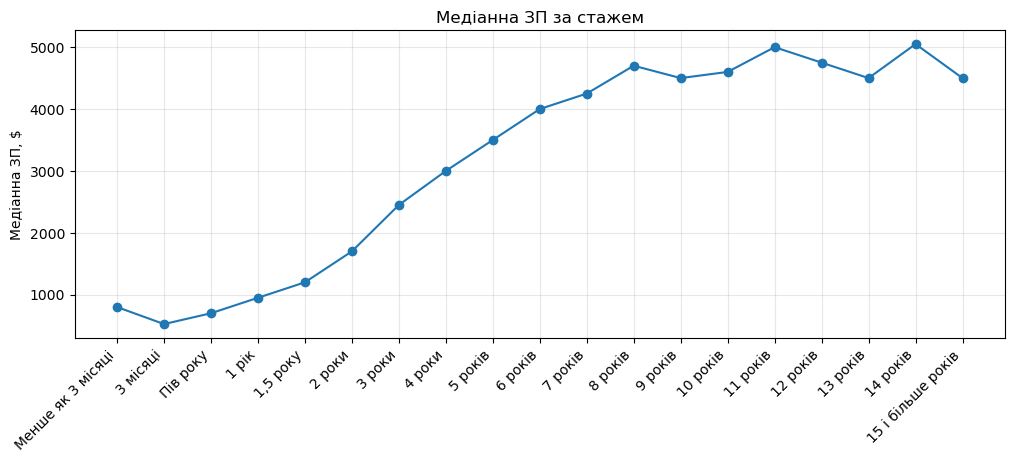

,"Медіанна ЗП, $"
Загальний стаж роботи за спеціальністю,
Менше як 3 місяці,800.0
3 місяці,525.0
Пів року,700.0
1 рік,950.0
"1,5 року",1200.0
2 роки,1700.0
3 роки,2450.0
4 роки,3000.0
5 років,3500.0


In [17]:
experience_col = 'Загальний стаж роботи за спеціальністю'
experience_order = ['Менше як 3 місяці', '3 місяці', 'Пів року', '1 рік', '1,5 року', '2 роки', '3 роки',
                    '4 роки', '5 років', '6 років', '7 років', '8 років', '9 років', '10 років',
                    '11 років', '12 років', '13 років', '14 років', '15 і більше років']
df[experience_col] = pd.Categorical(df[experience_col], categories=experience_order, ordered=True)

experience_salary = df.groupby(experience_col, observed=False)[salary_col].median()

plt.figure(figsize=(12, 4))
plt.plot(range(len(experience_order)), experience_salary.values, marker='o')
plt.xticks(range(len(experience_order)), experience_order, rotation=45, ha='right')
plt.title('Медіанна ЗП за стажем')
plt.ylabel('Медіанна ЗП, $')
plt.grid(alpha=0.3)
plt.show()

experience_salary.to_frame('Медіанна ЗП, $')

**Висновок.** Медіанна зарплата швидко зростає перші 8 років: 950 \$ за 1 рік стажу, 2 450 \$ за 3 роки, 3 500 \$ за 5 років і 4 700 \$ за 8 років. Найшвидше — між 1 і 4 роками: зарплата зростає більш як утричі. Після 8 років зростання майже зупиняється: медіана тримається біля 4 500–5 000 \$. Для стажу до року медіана — 525–800 \$: це переважно стажери, і різниця між цими групами невелика.

Далі тут можна зробити багато аналогічних агрегацій, проаналізувати, в який час люди заповнювали форму, хто більше отримує, Business Analyst, чи Data Analyst. Я вас заохочувати не стримувати свій інтерес і покапати ці дані далі :)

In [18]:
analyst_col = 'Ваша посада4'
df.groupby(analyst_col)[salary_col].agg(['median', 'count']).sort_values('median', ascending=False)

,median,count
Ваша посада4,,
Product Analyst,2550.0,34
Business Analyst,2250.0,289
System Analyst,2000.0,32
Data Analyst,1500.0,106
BI Analyst,1450.0,24


In [19]:
analysts = df[df[analyst_col].isin(['Business Analyst', 'Data Analyst'])]
analysts.pivot_table(index='Ваш тайтл', columns=analyst_col, values=salary_col,
                     aggfunc=['median', 'count'], observed=True)

median                         count             
Ваша посада4   Business Analyst Data Analyst Business Analyst Data Analyst
Ваш тайтл                                                                 
Intern/Trainee            600.0        325.0              4.0          1.0
Junior                   1115.0        880.0             46.0         33.0
Немає тайтлу             1250.0       1550.0             30.0         20.0
Middle                   2200.0       2000.0            116.0         33.0
Senior                   3800.0       2900.0             68.0         12.0
Tech Lead                3850.0          NaN              2.0          NaN
Team Lead                4500.0       1800.0             19.0          5.0
Architect                   NaN       2000.0              NaN          1.0
Head                     5200.0       4900.0              1.0          1.0
Manager                  2000.0          NaN              3.0          NaN

**Висновок.** Business Analyst загалом отримує більше, ніж Data Analyst: медіана 2 250 \$ проти 1 500 \$. Частково це пояснює рівень: серед Data Analyst майже третина — Junior, серед BA — 16 %. Але й на тому самому рівні BA отримує більше: Middle — 2 200 \$ проти 2 000 \$, Senior — 3 800 \$ проти 2 900 \$. Найвища медіана серед аналітиків — у Product Analyst (2 550 \$), але їх лише 34. Data Analyst теж небагато (106), тож висновок варто перевірити на свіжіших даних.